In [19]:

import pandas as pd
from functools import reduce
import numpy as np

In [20]:
CDR=pd.read_csv("Dane/cdr_d.csv")
CDR["Data"] = pd.to_datetime(CDR["Data"])
CDR = CDR.sort_values("Data")
CDR = CDR[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_CDR"})

KRU=pd.read_csv("Dane/kru_d.csv")
KRU["Data"] = pd.to_datetime(KRU["Data"])
KRU = KRU.sort_values("Data")
KRU = KRU[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_KRU"})

PKN=pd.read_csv("Dane/pkn_d.csv")
PKN["Data"] = pd.to_datetime(PKN["Data"])
PKN = PKN.sort_values("Data")
PKN = PKN[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_PKN"})

SGN=pd.read_csv("Dane/sgn_d.csv")
SGN["Data"] = pd.to_datetime(SGN["Data"])
SGN = SGN.sort_values("Data")
SGN = SGN[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_SGN"})

SNK=pd.read_csv("Dane/snk_d.csv")
SNK["Data"] = pd.to_datetime(SNK["Data"])
SNK = SNK.sort_values("Data")
SNK = SNK[["Data", "Zamkniecie"]].rename(columns={"Zamkniecie": "Close_SNK"})






In [21]:


dane = [CDR, KRU, PKN, SGN, SNK]

df = reduce(lambda left, right: pd.merge(left, right, on="Data", how="inner"), dane)

df = df.sort_values("Data").reset_index(drop=True)
df = df[(df["Data"] >= "2015-01-01") & (df["Data"] <= "2019-12-31")]
df = df.reset_index(drop=True)

In [22]:
cols = ["Close_CDR", "Close_KRU", "Close_PKN", "Close_SGN", "Close_SNK"]

df_pct = df.copy()

df_pct[cols] = (df[cols] / df[cols].iloc[0] - 1) * 100

df_pct

,Data,Close_CDR,Close_KRU,Close_PKN,Close_SGN,Close_SNK
0,2015-01-02,0.000000,0.000000,0.000000,0.000000,0.000000
1,2015-01-05,-1.068027,-0.404825,-1.647347,-1.391941,-0.404825
2,2015-01-07,0.237125,0.098509,2.860993,-3.003663,0.098509
3,2015-01-08,0.118884,3.207756,5.660695,0.366300,3.207756
4,2015-01-09,0.300102,6.900693,5.598687,1.318681,6.900693
...,...,...,...,...,...,...
1227,2019-12-19,1530.540954,59.746721,105.387929,-81.538462,59.746721
1228,2019-12-20,1539.029907,63.195798,102.403277,-81.098901,63.195798
1229,2019-12-23,1599.088771,63.195798,104.907274,-81.684982,63.195798
1230,2019-12-27,1585.111879,63.195798,106.832405,-81.318681,63.195798


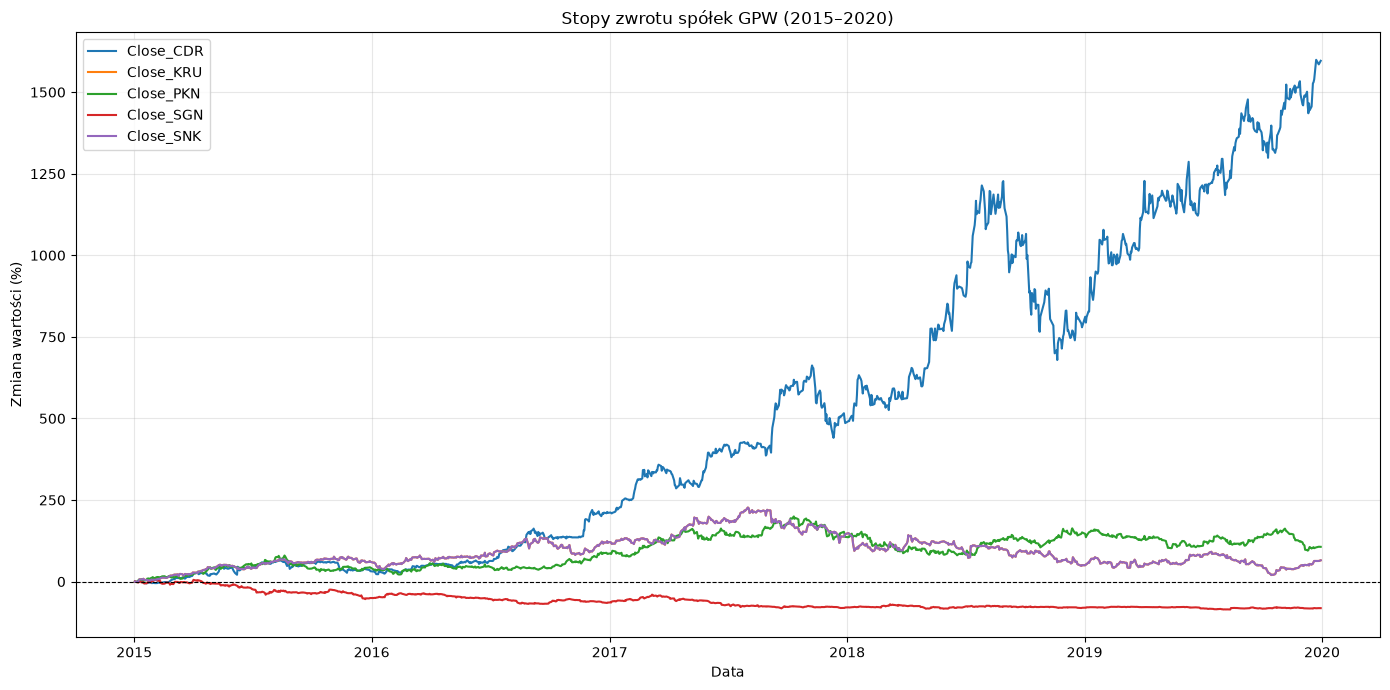

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

for col in cols:
    plt.plot(df_pct["Data"], df_pct[col], label=col)

plt.axhline(y=0, color="black", linewidth=0.8, linestyle="--")

plt.title("Stopy zwrotu spółek GPW (2015–2020)")
plt.xlabel("Data")
plt.ylabel("Zmiana wartości (%)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()